# [PROTOTYPE] Smooth lateral-colour model

**Status: approved 2026-10-10.** The cell labelled [APPROVED] writes `py_files/lateral_model_poly3.json`, which
`py_files/brick_lateralmaps.py` uses. Nothing here writes to the archive.

**Why:** the production lateral-colour maps (`ls-motions/lm-corrected-forced-motions/lateralmaps.fits`, Sept 2024,
16-px bins) are noise-dominated (bin-to-bin rms 17x the smooth signal) and were built from the pre-DR10 2024 forced
run. On DR10 data they *increase* per-epoch scatter (see PLAN.md "Lateral-colour (LM) diagnosis").

**What:** lateral colour is a smooth optical effect, so model the colour-dependent shift with a few parameters per
filter as a function of focal-plane position, fit to DR10 Gaia stars after DCR + ring-map corrections:

$$\Delta\mathbf{x} = (c - c_0)\,\mathbf{L}_b(u, v), \qquad c = g - i,\; c_0 = 1.642$$

Two forms of $\mathbf{L}_b$ are compared:
- **radial:** $\mathbf{L}_b = \left(\sum_{k=1}^{3} a_{b,k} R^{k}\right) \hat{\mathbf{R}}$ -- 3 parameters per filter;
- **poly:** independent 2-D polynomials of total order 3 in $(u, v)$ for each component -- 20 parameters per filter.

They are trained on half the bricks and evaluated on the other half, against the residual before lateral correction
(`rm`) and the current production correction (`lm`).

In [1]:
# [PROTOTYPE] setup
import os, glob, zlib
import numpy as np, fitsio
import matplotlib.pyplot as plt
from concurrent.futures import ProcessPoolExecutor

ARCHIVE = '/pscratch/sd/n/nelfalou/archive/legacypm-catalogue'
N_BRICKS = 200          # random subset of the 548 valid bricks (RA 060-063); raise on a compute node
C0 = 1.642              # pivot colour, same as brick_lateralmaps.median_color
PIX_MAS = 262.          # mas per pixel
FP_SCALE = 16000.       # focal-plane pixels -> u, v of order unity
FILTERS = ['g', 'r', 'i', 'z']

# CCD reference pixels in the focal plane (copied from err-plots.ipynb); fp = pixel - crpix
crpixes = {'S1': (2151.2, 14826.0), 'S2': (2151.2, 10566.67), 'S3': (2151.2, 6307.333), 'N1': (-103.2001, 14826.0),
 'N2': (-103.2001, 10566.67), 'N3': (-103.2001, 6307.333), 'S8': (4405.6, 12696.33), 'S9': (4405.6, 8437.0),
 'S14': (6660.0, 12696.33), 'S15': (6660.0, 8437.0), 'S20': (8914.4, 10566.67), 'S25': (11168.8, 8437.0),
 'N8': (-2357.6, 12696.33), 'N9': (-2357.6, 8437.0), 'N14': (-4612.0, 12696.33), 'N15': (-4612.0, 8437.0),
 'N20': (-6866.4, 10566.67), 'N25': (-9120.8, 8437.0), 'S10': (4405.6, 4177.667), 'S11': (4405.6, -81.66665),
 'S12': (4405.6, -4341.0), 'S13': (4405.6, -8600.334), 'S18': (6660.0, -4341.0), 'S19': (6660.0, -8600.334),
 'S16': (6660.0, 4177.667), 'S17': (6660.0, -81.66665), 'S21': (8914.4, 6307.333), 'S22': (8914.4, 2048.0),
 'S23': (8914.4, -2211.333), 'S24': (8914.4, -6470.667), 'S26': (11168.8, 4177.667), 'S27': (11168.8, -81.66665),
 'S28': (11168.8, -4341.0), 'S29': (13423.2, 6307.333), 'S30': (13423.2, 2048.0), 'S31': (13423.2, -2211.333),
 'N4': (-103.2001, 2048.0), 'N5': (-103.2001, -2211.333), 'N6': (-103.2001, -6470.667), 'N7': (-103.2001, -10730.0),
 'S4': (2151.2, 2048.0), 'S5': (2151.2, -2211.333), 'S6': (2151.2, -6470.667), 'S7': (2151.2, -10730.0),
 'N10': (-2357.6, 4177.667), 'N11': (-2357.6, -81.66665), 'N12': (-2357.6, -4341.0), 'N13': (-2357.6, -8600.334),
 'N18': (-4612.0, -4341.0), 'N19': (-4612.0, -8600.334), 'N16': (-4612.0, 4177.667), 'N17': (-4612.0, -81.66665),
 'N21': (-6866.4, 6307.333), 'N22': (-6866.4, 2048.0), 'N23': (-6866.4, -2211.333), 'N24': (-6866.4, -6470.667),
 'N26': (-9120.8, 4177.667), 'N27': (-9120.8, -81.66665), 'N28': (-9120.8, -4341.0), 'N29': (-11375.2, 6307.333),
 'N30': (-11375.2, 2048.0), 'N31': (-11375.2, -2211.333), 'FS1': (11168.8, -8600.334), 'FS2': (13423.2, -6470.667),
 'FS3': (15677.6, -81.6666), 'FS4': (15677.6, 2129.667), 'FN1': (-9120.8, -8600.334), 'FN2': (-11375.2, -6470.667),
 'FN3': (-13629.6, -81.6666), 'FN4': (-13629.6, 2129.667)}

def rsig(v):
    v = v[np.isfinite(v)]
    return 1.4826 * np.median(np.abs(v - np.median(v)))

In [2]:
# [PROTOTYPE] load Gaia-star measurements from the archive (build cut: sigma < 10 mas, dqmask == 0, valid fit)
FCOLS = ['objid', 'ccdname', 'filter', 'x', 'y', 'rm_full_fit_x', 'rm_full_fit_y', 'lm_full_fit_x', 'lm_full_fit_y',
         'full_fit_dra', 'full_fit_dra_ivar', 'dqmask']
TCOLS = ['ref_cat', 'flux_g', 'flux_i']

def load_brick(pm_path):
    brick = os.path.basename(pm_path)[11:19]
    try:
        T = fitsio.read(pm_path, columns=TCOLS)
        F = fitsio.read(os.path.join(os.path.dirname(pm_path), f'forced-{brick}.fits'), columns=FCOLS)
    except Exception:
        return None   # e.g. forced-0630m797 (no data), forced-0623m300 (no rm_ columns)
    F = F[(F['x'] != 0) & (F['full_fit_dra_ivar'] > 1e4) & (F['full_fit_dra'] != 0) & (F['dqmask'] == 0)
          & (F['objid'] < len(T))]
    o = F['objid']
    gaia = np.char.strip(T['ref_cat'].astype(str)) == 'GE'
    with np.errstate(all='ignore'):
        col = -2.5 * np.log10(T['flux_g'] / T['flux_i'])
    keep = gaia[o] & np.isfinite(col[o]) & (col[o] > -0.5) & (col[o] < 4.0)
    F = F[keep]
    out = {k: F[k] for k in FCOLS if k not in ('full_fit_dra', 'full_fit_dra_ivar', 'dqmask')}
    out['c'] = col[F['objid']]
    out['brick'] = np.full(len(F), brick)
    return out

paths = sorted(p for d in ['060', '061', '062', '063'] for p in glob.glob(f'{ARCHIVE}/{d}/tractor-pm-*.fits')
               if os.path.getsize(p) > 0)
paths = list(np.random.default_rng(42).choice(paths, N_BRICKS, replace=False))
with ProcessPoolExecutor(8) as ex:
    parts = [p for p in ex.map(load_brick, paths) if p is not None]
D = {k: np.concatenate([p[k] for p in parts]) for k in parts[0]}
D['ccdname'] = np.char.strip(D['ccdname'].astype(str))
D['filter'] = np.char.strip(D['filter'].astype(str))
ok = np.isin(D['ccdname'], list(crpixes))
D = {k: v[ok] for k, v in D.items()}

cp = np.array([crpixes[c] for c in D['ccdname']])
D['u'] = (D['rm_full_fit_x'] - cp[:, 0]) / FP_SCALE
D['v'] = (D['rm_full_fit_y'] - cp[:, 1]) / FP_SCALE
D['res_x'] = D['rm_full_fit_x'] - D['x']        # residual after DCR + ring maps (pixels)
D['res_y'] = D['rm_full_fit_y'] - D['y']
D['old_x'] = D['rm_full_fit_x'] - D['lm_full_fit_x']   # correction applied by the production lateral maps
D['old_y'] = D['rm_full_fit_y'] - D['lm_full_fit_y']
D['dc'] = D['c'] - C0
# train/test split by brick (deterministic)
D['test'] = np.array([zlib.crc32(b.encode()) % 2 == 1 for b in D['brick']])
print(f"{len(parts)} bricks loaded, {len(D['u']):,} Gaia-star measurements "
      f"({(~D['test']).sum():,} train / {D['test'].sum():,} test)")
for f in FILTERS:
    print(f'  {f}: {(D["filter"] == f).sum():,}')

200 bricks loaded, 508,678 Gaia-star measurements (260,860 train / 247,818 test)
  g: 78,315
  r: 111,040
  i: 162,492
  z: 156,831


## [PROTOTYPE] Model fit

Per CCD and filter, the median residual is subtracted before fitting. This is a nuisance offset that the ring maps
should already remove; it isn't part of the lateral correction. The fit is iteratively 3-sigma-clipped least squares.

In [3]:
# [PROTOTYPE] design matrices and robust fit
POLY_TERMS = [(i, j) for i in range(4) for j in range(4 - i)]     # u^i v^j, i + j <= 3 (10 terms)

def design(model, u, v, dc):
    """Return (Ax, Ay): rows predicting the x and y shifts (pixels)."""
    if model == 'radial':
        R = np.hypot(u, v)
        Ax = np.stack([dc * R**(k - 1) * u for k in (1, 2, 3)], 1)   # a_k R^k * (u/R)
        Ay = np.stack([dc * R**(k - 1) * v for k in (1, 2, 3)], 1)
        return Ax, Ay                                                 # shared coefficients
    P = np.stack([u**i * v**j for i, j in POLY_TERMS], 1) * dc[:, None]
    Z = np.zeros_like(P)
    return np.hstack([P, Z]), np.hstack([Z, P])                       # independent x and y polynomials

def remove_offsets(m):
    rx, ry = D['res_x'][m].copy(), D['res_y'][m].copy()
    key = np.char.add(D['ccdname'][m], D['filter'][m])
    for k in np.unique(key):
        s = key == k
        rx[s] -= np.median(rx[s]); ry[s] -= np.median(ry[s])
    return rx, ry

def robust_lstsq(A, y, n_iter=6):
    w = np.ones(len(y), bool)
    for _ in range(n_iter):
        coef = np.linalg.lstsq(A[w], y[w], rcond=None)[0]
        r = y - A @ coef
        w = np.abs(r) < 3 * rsig(r[w])
    return coef

def predict(model, coef, m):
    Ax, Ay = design(model, D['u'][m], D['v'][m], D['dc'][m])
    return Ax @ coef, Ay @ coef

COEF = {}
for f in FILTERS:
    m = (~D['test']) & (D['filter'] == f)
    rx, ry = remove_offsets(m)
    for model in ('radial', 'poly'):
        Ax, Ay = design(model, D['u'][m], D['v'][m], D['dc'][m])
        COEF[(model, f)] = robust_lstsq(np.vstack([Ax, Ay]), np.concatenate([rx, ry]))
    a = COEF[('radial', f)] * PIX_MAS
    print(f'{f}: radial a_k = {a[0]:+.2f}, {a[1]:+.2f}, {a[2]:+.2f} mas/mag  '
          f'(shift at R=1, i.e. ~16000 px, per mag of colour: {a.sum():+.2f} mas)')

g: radial a_k = +7.06, -37.51, +57.44 mas/mag  (shift at R=1, i.e. ~16000 px, per mag of colour: +26.99 mas)


r: radial a_k = +4.54, -26.79, +31.75 mas/mag  (shift at R=1, i.e. ~16000 px, per mag of colour: +9.50 mas)


i: radial a_k = +2.33, -11.39, +12.34 mas/mag  (shift at R=1, i.e. ~16000 px, per mag of colour: +3.27 mas)


z: radial a_k = -2.18, +2.76, -0.13 mas/mag  (shift at R=1, i.e. ~16000 px, per mag of colour: +0.45 mas)


## [PROTOTYPE] Evaluation on held-out bricks

For each filter and colour bin: the per-axis robust scatter of the residual (mas) with no lateral correction
(`none`), with the production maps (`old`), and with each new model. `useful` = Cov(r, d) / Var(d): the fraction of
the applied correction that tracks the residual (1 = all signal; < 0.5 means it hurts).

In [4]:
# [PROTOTYPE] held-out comparison
def useful_frac(rx, ry, dx, dy):
    # Cov(r, d) / Var(d) on measurements with |r| < 5 robust sigma (plain moments; a MAD-based covariance is
    # unreliable when d is small and smooth)
    num = den = 0.
    for r, d in ((rx, dx), (ry, dy)):
        d = np.broadcast_to(d, r.shape)
        k = np.abs(r - np.median(r)) < 5 * rsig(r)
        rr, dd = r[k] - r[k].mean(), d[k] - d[k].mean()
        num += np.mean(rr * dd); den += np.mean(dd * dd)
    return num / den if den > 0 else np.nan

bins = {'blue c<0.92': lambda c: c < 0.92, 'mid': lambda c: (c >= 0.92) & (c <= 2.33), 'red c>2.33': lambda c: c > 2.33}
rows = []
for f in FILTERS:
    for bname, bfun in bins.items():
        m = D['test'] & (D['filter'] == f) & bfun(D['c'])
        if m.sum() < 500:
            continue
        rx, ry = D['res_x'][m], D['res_y'][m]
        corr = {'old': (D['old_x'][m], D['old_y'][m])}
        for model in ('radial', 'poly'):
            corr[model] = predict(model, COEF[(model, f)], m)
        line = {'filter': f, 'bin': bname, 'N': m.sum(),
                'none': PIX_MAS * np.mean([rsig(rx), rsig(ry)])}
        for k, (dx, dy) in corr.items():
            line[k] = PIX_MAS * np.mean([rsig(rx - dx), rsig(ry - dy)])
            line[k + '_useful'] = useful_frac(rx, ry, dx, dy)
        rows.append(line)

print(f"{'filt':4s} {'colour bin':12s} {'N':>7s} | {'none':>6s} {'old':>6s} {'radial':>6s} {'poly':>6s}  (mas)"
      f" | useful: {'old':>5s} {'radial':>6s} {'poly':>5s}")
for r in rows:
    print(f"{r['filter']:4s} {r['bin']:12s} {r['N']:7d} | {r['none']:6.2f} {r['old']:6.2f} {r['radial']:6.2f} "
          f"{r['poly']:6.2f}        |         {r['old_useful']:+5.2f} {r['radial_useful']:+6.2f} {r['poly_useful']:+5.2f}")

filt colour bin         N |   none    old radial   poly  (mas) | useful:   old radial  poly
g    blue c<0.92    14284 |  20.36  20.47  19.43  19.44        |         +0.28  +1.15 +1.17
g    mid            20278 |  18.94  19.11  18.80  18.79        |         +0.21  +1.13 +1.12
g    red c>2.33      5007 |  18.77  22.33  17.91  18.00        |         -0.11  +1.00 +1.03
r    blue c<0.92    13775 |  14.33  15.17  14.24  14.24        |         +0.13  +0.90 +0.97
r    mid            26967 |  15.49  15.72  15.51  15.52        |         +0.03  +1.31 +1.19
r    red c>2.33     14729 |  15.65  17.03  15.60  15.60        |         -0.07  +0.79 +0.67
i    blue c<0.92    12548 |  11.98  12.98  11.91  11.90        |         -0.02  +2.81 +0.29
i    mid            35248 |  11.85  12.06  11.82  11.83        |         -0.03  +2.11 +0.64
i    red c>2.33     31531 |  13.35  14.92  13.37  13.32        |         +0.03  +0.12 +0.61
z    blue c<0.92    10817 |  10.29  11.65  10.28  10.33        |         -0.05  

## [PROTOTYPE] Radial profile: data vs models

In bins of focal-plane radius, the slope of the radial residual against $(c - c_0)$ (mas per mag), measured on the
held-out bricks, compared with what each correction applies. A good model follows the data points.

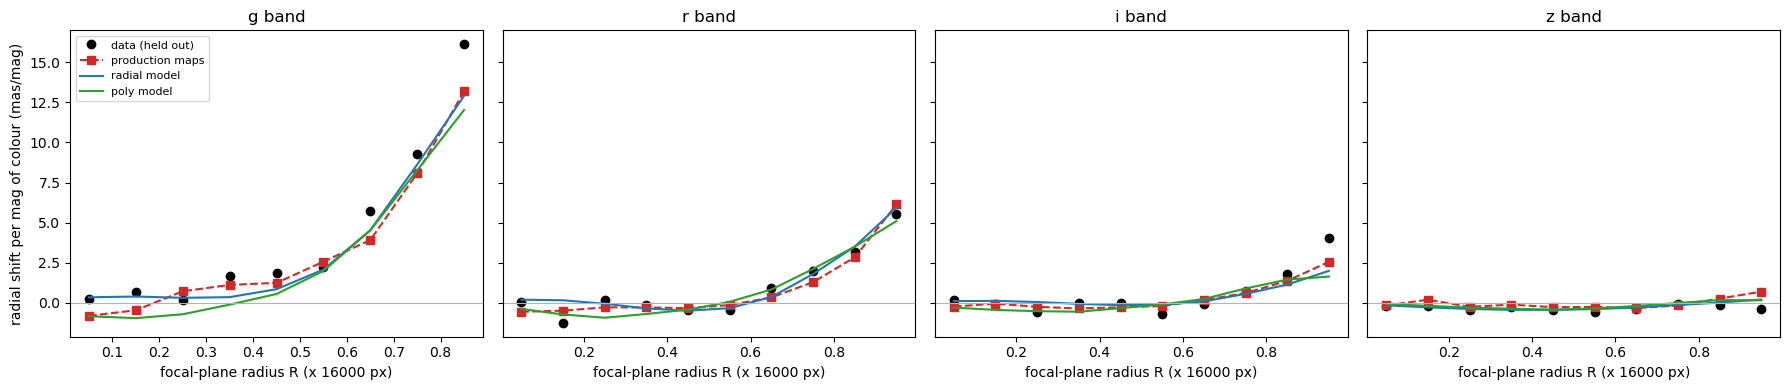

In [5]:
# [PROTOTYPE] radial-profile figure
def slope(x, y):
    w = np.isfinite(x) & np.isfinite(y)
    x, y = x[w], y[w]
    for _ in range(4):
        A = np.vstack([x, np.ones_like(x)]).T
        s, i = np.linalg.lstsq(A, y, rcond=None)[0]
        r = y - (s * x + i); k = np.abs(r) < 3 * rsig(r)
        x, y = x[k], y[k]
    return s

def radial(dx, dy, m):
    R = np.hypot(D['u'][m], D['v'][m])
    return (dx * D['u'][m] + dy * D['v'][m]) / R

redges = np.linspace(0.0, 1.0, 11)
fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
for ax, f in zip(axes, FILTERS):
    prof = {k: [] for k in ('data', 'old', 'radial', 'poly')}; rc = []
    for lo, hi in zip(redges, redges[1:]):
        m = D['test'] & (D['filter'] == f) & (np.hypot(D['u'], D['v']) >= lo) & (np.hypot(D['u'], D['v']) < hi)
        if m.sum() < 300:
            continue
        rc.append((lo + hi) / 2)
        prof['data'].append(slope(D['dc'][m], radial(D['res_x'][m], D['res_y'][m], m)))
        prof['old'].append(slope(D['dc'][m], radial(D['old_x'][m], D['old_y'][m], m)))
        for model in ('radial', 'poly'):
            dx, dy = predict(model, COEF[(model, f)], m)
            prof[model].append(slope(D['dc'][m], radial(dx, dy, m)))
    ax.plot(rc, PIX_MAS * np.array(prof['data']), 'ko', label='data (held out)')
    ax.plot(rc, PIX_MAS * np.array(prof['old']), 's--', color='C3', label='production maps')
    ax.plot(rc, PIX_MAS * np.array(prof['radial']), '-', color='C0', label='radial model')
    ax.plot(rc, PIX_MAS * np.array(prof['poly']), '-', color='C2', label='poly model')
    ax.axhline(0, color='0.7', lw=0.8)
    ax.set_title(f'{f} band'); ax.set_xlabel('focal-plane radius R (x 16000 px)')
axes[0].set_ylabel('radial shift per mag of colour (mas/mag)')
axes[0].legend(fontsize=8)
plt.tight_layout()

## [PROTOTYPE] Remaining colour dependence per CCD

Per CCD and filter, the slope of the residual against $(c - c_0)$ on held-out bricks, before and after each
correction. Median |slope| in mas/mag; smaller is better.

In [6]:
# [PROTOTYPE] per-CCD remaining colour slope
res = {k: [] for k in ('none', 'old', 'radial', 'poly')}
for f in FILTERS:
    for ccd in np.unique(D['ccdname']):
        m = D['test'] & (D['filter'] == f) & (D['ccdname'] == ccd)
        if m.sum() < 400:
            continue
        cand = {'none': (0, 0), 'old': (D['old_x'][m], D['old_y'][m])}
        for model in ('radial', 'poly'):
            cand[model] = predict(model, COEF[(model, f)], m)
        for k, (dx, dy) in cand.items():
            for r, d in ((D['res_x'][m], dx), (D['res_y'][m], dy)):
                res[k].append(slope(D['dc'][m], r - d))
for k, v in res.items():
    print(f'{k:7s}: median |slope| = {PIX_MAS * np.nanmedian(np.abs(v)):.2f} mas/mag   (N = {len(v)} CCD-filter-axes)')

none   : median |slope| = 1.23 mas/mag   (N = 472 CCD-filter-axes)
old    : median |slope| = 0.80 mas/mag   (N = 472 CCD-filter-axes)
radial : median |slope| = 1.14 mas/mag   (N = 472 CCD-filter-axes)
poly   : median |slope| = 0.71 mas/mag   (N = 472 CCD-filter-axes)


## [APPROVED 2026-10-10] Final fit and coefficients file used by the pipeline

Refits the **poly** model on *all* loaded bricks (train + test) and writes `py_files/lateral_model_poly3.json`,
which `brick_lateralmaps.py` reads. Re-run this notebook to regenerate it, e.g. with more bricks.

In [7]:
# [APPROVED] fit poly model on all bricks and write the pipeline's coefficients file
import json, datetime
OUT = os.path.abspath('../py_files/lateral_model_poly3.json')
final = {}
for f in FILTERS:
    m = D['filter'] == f
    rx, ry = remove_offsets(m)
    Ax, Ay = design('poly', D['u'][m], D['v'][m], D['dc'][m])
    final[f] = robust_lstsq(np.vstack([Ax, Ay]), np.concatenate([rx, ry])).tolist()
model = {
    'description': 'Smooth lateral-colour model: shift (pixels) = (c - c0) * [Px(u,v), Py(u,v)], c = g - i (mag), '
                   'u = (x - crpix_x) / fp_scale, v = (y - crpix_y) / fp_scale, x/y = rm_full_fit_x/y. '
                   'coef[filter] = 10 x-terms then 10 y-terms, in the order of poly_terms (u^i v^j). '
                   'Subtract the shift from rm_full_fit_x/y.',
    'c0': C0, 'fp_scale': FP_SCALE, 'units': 'pixels per mag',
    'poly_terms': POLY_TERMS, 'coef': final, 'crpixes': crpixes,
    'fit': {'notebook': 'run/lateral-model.ipynb', 'date': str(datetime.date.today()),
            'n_bricks': len(parts), 'n_measurements': int(len(D['u'])),
            'selection': 'Gaia stars, full_fit_dra_ivar > 1e4, dqmask == 0, -0.5 < g-i < 4; residual = rm - expected'},
}
with open(OUT, 'w') as fh:
    json.dump(model, fh, indent=1)
print('wrote', OUT)
for f in FILTERS:
    m = D['filter'] == f
    dx, dy = predict('poly', np.array(final[f]), m)
    print(f'  {f}: rms applied shift {PIX_MAS * np.sqrt(np.mean(dx**2 + dy**2)):.2f} mas')

wrote /pscratch/sd/n/nelfalou/LegacyPM/py_files/lateral_model_poly3.json
  g: rms applied shift 5.35 mas
  r: rms applied shift 1.65 mas
  i: rms applied shift 2.21 mas


  z: rms applied shift 0.51 mas


## [PROTOTYPE] Notes for review

- Sample: Gaia stars in a random subset of the 548 archived bricks (RA 060-063). Every exposure covers the whole
  focal plane, so focal-plane coverage is complete even though the sky area is small.
- Approved 2026-10-10: the poly model is wired into `brick_lateralmaps.py` via the coefficients file written above.